# IA26_P01_G02 — Agente de routing para distribuição de produtos locais
**Inteligência Artificial 2026/27 · Licenciatura em Engenharia de Sistemas Informáticos (IPCA)**  
**Trabalho Prático 1 · Notebook 01 — Introdução e Análise Exploratória de Dados (EDA)**

| Nome | Nº de aluno |
|---|---|
| André Rodrigues | 26900 |
| Tiago Gonçalves | 29389 |
| Fábio Ferreira | 29365 |
| Alexandre Silva | 29382 |

Repositório: https://github.com/FabioFerreira2005/IA26_P01_G02

## 0. Introdução

### 0.1 Contexto
Na União Europeia tem crescido a procura por alimentos produzidos localmente. As cadeias de abastecimento curtas reduzem as emissões associadas ao transporte e o desperdício alimentar quando comparadas com a distribuição de longa distância. No entanto, os pequenos produtores enfrentam custos logísticos elevados e uma forte volatilidade de preços, em particular nas frutas e legumes, cujos preços subiram significativamente nos últimos anos.

Este projeto enquadra-se numa **plataforma digital que liga três tipos de atores**:

- **Produtores** — pequenas explorações agrícolas locais que oferecem fruta, legumes e outros produtos;
- **Clientes** — fazem encomendas e escolhem o local onde as querem receber (casa, loja, restaurante, …);
- **Centros de recolha (armazéns)** — agregam os produtos antes da distribuição e são a base de uma frota de veículos.

O cenário cobre o **distrito de Braga** (incluindo a Póvoa de Varzim) e é suportado por um conjunto de dados sintético em CSV.

### 0.2 O problema
O desafio central é o **routing**: decidir que veículo faz cada recolha e cada entrega, e por que ordem, de modo a minimizar a distância percorrida, respeitando:

- o **fluxo obrigatório** produtor → armazém → local de entrega (todos os produtos passam pelo centro de recolha);
- as **janelas de disponibilidade** de cada produto no produtor e as **janelas de entrega** de cada encomenda;
- a **capacidade** (kg) de cada veículo;
- os **tempos de serviço** em cada paragem e de manuseamento no armazém, e o **tempo máximo de permanência** no armazém (`rules.csv`).

Trata-se de uma variante do *Pickup and Delivery Problem with Time Windows* (PDPTW) com passagem obrigatória por um ponto de consolidação.

### 0.3 Objetivo
Desenvolver um **agente inteligente** que, a partir dos dados da plataforma, encontre rotas de recolha e entrega eficientes e viáveis, aplicando e comparando técnicas de IA:

1. **Pesquisa informada** — Greedy Best-First e A\* com duas heurísticas próprias, usando a Pesquisa de Custo Uniforme (UCS) para validar a solução ótima;
2. **Problemas de Satisfação de Restrições (CSP)** — janelas temporais, capacidade e permanência no armazém como restrições, com a biblioteca `python-constraint`;
3. **Pesquisa local** (extra) — Hill-Climbing para melhorar a solução obtida pelo Greedy.

### 0.4 Organização do trabalho
| Fase | Entregável |
|---|---|
| Introdução e EDA *(este notebook)* | `01_eda_tiny.ipynb` |
| Modelação | `model.py` (classes `Problem`, `Request`, `Vehicle`, `State`, função de custo e verificador de viabilidade) + testes |
| Pesquisa informada | Rotas para os 2 veículos do conjunto *tiny*, nós expandidos por algoritmo |
| CSP | Formulação (variáveis, domínios, restrições), atribuição viável e nº de backtracks |
| Pesquisa local | Curvas de custo por iteração |
| Análise de resultados e conclusão | Comparação de algoritmos, tempos de execução, melhorias futuras |

### 0.5 Dados
São fornecidos dois conjuntos de dados em `docs/`, ambos com 12 ficheiros CSV e o mesmo esquema:

- `data_tiny` — instância pequena, analisada neste notebook;
- `data_small_30_31oct2026` — instância maior, analisada no notebook `01_eda_small.ipynb` e comparada com a *tiny* no final desta EDA.

### 0.6 Organização do código
O código está dividido em módulos Python, e o notebook usa as suas funções:

| Ficheiro | Papel |
|---|---|
| `loader.py` | Leitura dos CSVs (*parsing*) e preparação das tabelas |
| `windows.py` | Cálculos com as janelas temporais: durações, folgas e permanência no armazém |
| `01_eda_tiny.ipynb` | EDA do conjunto *tiny*: chama as funções, mostra os resultados e os gráficos, e explica as conclusões |
| `01_eda_small.ipynb` | A mesma análise para o conjunto *small* |

Assim, o mesmo código de leitura poderá ser reutilizado nas fases seguintes (modelação, pesquisa e CSP).

Para reproduzir: `pip install -r requirements.txt` e executar todas as células (*Run All*).

## 1. Análise Exploratória de Dados (EDA)

Nesta secção estudamos o conjunto de dados **tiny** antes de modelar o problema. Para cada passo indicamos o **objetivo**, apresentamos o código e registamos as **observações** que retiramos do resultado.

### 1.1 Bibliotecas e leitura dos dados

**Objetivo:** carregar os 12 ficheiros CSV para memória.

A leitura está na função `carregar_dados` do módulo `loader.py`. Esta função lê cada ficheiro com `pd.read_csv` para uma tabela (`DataFrame`) e, nas tabelas com datas, usa o parâmetro `parse_dates` para converter essas colunas de texto para o tipo data e hora (*parsing*). Sem esta conversão não seria possível comparar horas nem calcular durações.

A função devolve um dicionário com uma tabela por ficheiro, por exemplo `dados["products"]`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)                   # mostrar sempre todas as colunas das tabelas

# funções do projeto
from loader import carregar_dados, construir_pedidos, paragem_armazem, matriz_paragens, criar_estruturas
from windows import duracao_horas, hora_decimal, calcular_folgas, calcular_permanencias

PASTA = "docs/data_tiny/"
dados = carregar_dados(PASTA)

# uma variável por tabela, para o código seguinte ficar mais legível
localities         = dados["localities"]
producers          = dados["producers"]
products           = dados["products"]
collection_centers = dados["collection_centers"]
vehicles           = dados["vehicles"]
customers          = dados["customers"]
delivery_locations = dados["delivery_locations"]
orders             = dados["orders"]
order_items        = dados["order_items"]
locations          = dados["locations"]
distance_matrix    = dados["distance_matrix"]
rules              = dados["rules"]

### 1.2 Dataset em memória: linhas de cada tabela

**Objetivo:** confirmar que o dataset ficou em memória, ver quantas linhas e colunas tem cada tabela, mostrar as primeiras linhas de cada uma e confirmar que as datas foram bem convertidas.

In [2]:
# o dicionário devolvido por carregar_dados permite percorrer todas as tabelas num ciclo
tabelas = dados

for nome, tabela in tabelas.items():
    print(f"{nome:20s} {tabela.shape[0]:4d} linhas   {tabela.shape[1]:2d} colunas")

localities             49 linhas    6 colunas
producers               3 linhas    6 colunas
products               15 linhas    6 colunas
collection_centers      1 linhas    5 colunas
vehicles                2 linhas    6 colunas
customers              12 linhas    5 colunas
delivery_locations      5 linhas    5 colunas
orders                 12 linhas    5 colunas
order_items            40 linhas    9 colunas
locations               9 linhas    7 colunas
distance_matrix        72 linhas    6 colunas
rules                  10 linhas    3 colunas


As primeiras 5 linhas de cada tabela, tal como ficaram em memória depois da leitura. Para ver uma tabela completa basta escrever o seu nome numa célula, por exemplo `dados["orders"]`.

In [3]:
for nome, tabela in tabelas.items():
    print(f"{nome}  ({len(tabela)} linhas)")
    display(tabela.head())

localities  (49 linhas)


,locality_id,name,municipality,district,latitude,longitude
0,1,Se,Braga,Braga,41.533518,-8.405528
1,2,Maximinos,Braga,Braga,41.564989,-8.435147
2,3,Real,Braga,Braga,41.551572,-8.425425
3,4,Nogueiro,Braga,Braga,41.559380,-8.408464
4,5,Dume,Braga,Braga,41.531493,-8.446483


producers  (3 linhas)


,producer_id,name,locality_id,address,phone,email
0,1,Hortas Valente,24,"Largo Amaral, S/N",(351) 928 063 608,veramatos@oliveira.net
1,2,Campos Leite,40,"Praça Nuno Alves, 28",(351) 924 158 683,noa97@pinho.com
2,3,Horta Morais,36,"Alameda do Ouro, 6",+351961781286,debora07@goncalves.com


products  (15 linhas)


,product_id,producer_id,name,category,unit,unit_weight_kg
0,1,1,Pimento,vegetable,kg,1.0
1,2,1,Kiwi,fruit,kg,1.0
2,3,1,Cereja,fruit,kg,1.0
3,4,1,Pera,fruit,kg,1.0
4,5,1,Batata,vegetable,kg,1.0


... (14 outputs left out)

distance_matrix  (72 linhas)


,origin_location_id,origin_type,destination_location_id,destination_type,distance_km,duration_min
0,1,producer,2,producer,23.59,31.4
1,1,producer,3,producer,39.30,52.4
2,1,producer,4,collection_center,30.60,40.8
3,1,producer,5,delivery_location,13.45,17.9
4,1,producer,6,delivery_location,66.45,88.6


rules  (10 linhas)


,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...


In [4]:
# tipo de cada coluna: as janelas devem aparecer como datetime64
order_items.dtypes.rename_axis("coluna").to_frame("tipo")

,tipo
coluna,
order_item_id,int64
order_id,int64
product_id,int64
quantity,float64
weight_kg,float64
availability_start,datetime64[us]
availability_end,datetime64[us]
delivery_start,datetime64[us]
delivery_end,datetime64[us]


**Observações:** o problema é pequeno: 3 produtores, 1 centro de recolha, 5 locais de entrega, 2 veículos, 12 encomendas e 40 itens. A matriz de distâncias tem 72 linhas, uma por cada par de paragens. As quatro colunas das janelas temporais ficaram com o tipo `datetime64`, ou seja, o *parsing* das datas foi feito corretamente.

### 1.3 Contagem por tipo e grupo

**Objetivo:** contar quantos elementos existem de cada tipo em cada grupo de dados.

A função `value_counts()` conta quantas vezes aparece cada valor numa coluna. Para a contagem ser apresentada como uma tabela formatada, convertemo-la num `DataFrame` com `to_frame()`, damos nomes claros às colunas com `rename_axis()` e traduzimos os valores para português com `replace()`.

In [5]:
# nomes em português para os tipos de paragem, locais de entrega e categorias
TIPOS = {"producer": "produtor", "collection_center": "centro de recolha", "delivery_location": "local de entrega",
         "home": "casa", "store": "loja", "market": "mercado", "restaurant": "restaurante"}
CATEGORIAS = {"vegetable": "legumes", "fruit": "fruta", "other": "outros"}
UNIDADES = {"kg": "kg", "unit": "unidade", "crate": "caixa"}
ESTADOS = {"confirmed": "confirmada", "placed": "registada", "delivered": "entregue"}

In [6]:
# paragens e locais de entrega
display(locations["location_type"].replace(TIPOS).value_counts()
        .rename_axis("tipo de paragem").to_frame("nº de paragens"))

display(delivery_locations["location_type"].replace(TIPOS).value_counts()
        .rename_axis("tipo de local de entrega").to_frame("nº de locais"))

,nº de paragens
tipo de paragem,
local de entrega,5
produtor,3
centro de recolha,1


,nº de locais
tipo de local de entrega,
casa,3
loja,2


In [7]:
# produtos
display(products["category"].replace(CATEGORIAS).value_counts()
        .rename_axis("categoria").to_frame("nº de produtos"))

display(products["unit"].replace(UNIDADES).value_counts()
        .rename_axis("unidade de venda").to_frame("nº de produtos"))

# nome do produtor em vez do id
produtos_produtor = products.merge(producers[["producer_id", "name"]], on="producer_id", suffixes=("", "_produtor"))
display(produtos_produtor["name_produtor"].value_counts()
        .rename_axis("produtor").to_frame("nº de produtos"))

,nº de produtos
categoria,
legumes,7
fruta,6
outros,2


,nº de produtos
unidade de venda,
kg,13
unidade,1
caixa,1


,nº de produtos
produtor,
Hortas Valente,6
Campos Leite,5
Horta Morais,4


In [8]:
# encomendas
display(orders["status"].replace(ESTADOS).value_counts()
        .rename_axis("estado").to_frame("nº de encomendas"))

# nome do local de entrega em vez do id
encomendas_local = orders.merge(delivery_locations[["delivery_location_id", "name"]], on="delivery_location_id")
display(encomendas_local["name"].value_counts().sort_index()
        .rename_axis("local de entrega").to_frame("nº de encomendas"))

# número de itens de cada encomenda (tabela na horizontal, com todas as encomendas)
itens_por_encomenda = order_items["order_id"].value_counts().sort_index()
display(itens_por_encomenda.rename_axis("encomenda").to_frame("nº de itens").T)

# resumo: quantas encomendas têm 2, 3, 4, ... itens
display(itens_por_encomenda.value_counts().sort_index()
        .rename_axis("nº de itens").to_frame("nº de encomendas"))

,nº de encomendas
estado,
confirmada,12


,nº de encomendas
local de entrega,
Casa 2,3
Casa 3,3
Casa 4,2
Loja 1,2
Loja 5,2


encomenda,1,2,3,4,5,6,7,8,9,10,11,12
nº de itens,4,2,4,3,2,2,4,3,5,2,4,5


,nº de encomendas
nº de itens,
2,4
3,2
4,4
5,2


In [9]:
# veículos
veiculos = vehicles[["vehicle_id", "capacity_kg", "refrigerated"]].copy()
veiculos["refrigerated"] = veiculos["refrigerated"].replace({1: "sim", 0: "não"})
veiculos.rename(columns={"vehicle_id": "veículo", "capacity_kg": "capacidade (kg)", "refrigerated": "refrigerado"})

,veículo,capacidade (kg),refrigerado
0,1,150.0,sim
1,2,200.0,não


**Observações:**
- Há 9 paragens: 5 locais de entrega (3 casas e 2 lojas), 3 produtores e 1 centro de recolha.
- Os 15 produtos são sobretudo legumes (7) e fruta (6). A maioria é vendida ao kg, mas há produtos vendidos à unidade (mel) e à caixa (ovos). Por isso, nas restrições de capacidade vamos usar o peso em kg e não a quantidade.
- Todas as 12 encomendas estão confirmadas e têm entre 2 e 5 itens.
- Um dos veículos é refrigerado (150 kg) e o outro não (200 kg).

### 1.4 Qualidade dos dados

**Objetivo:** confirmar que os dados não têm erros antes de os usarmos.

Verificamos quatro aspetos: valores em falta, identificadores repetidos, referências entre tabelas e coerência do peso.

In [10]:
# 1) valores em falta em cada tabela
for nome, tabela in tabelas.items():
    print(f"{nome:20s} valores em falta: {tabela.isna().sum().sum()}")

localities           valores em falta: 0
producers            valores em falta: 0
products             valores em falta: 0
collection_centers   valores em falta: 0
vehicles             valores em falta: 0
customers            valores em falta: 0
delivery_locations   valores em falta: 0
orders               valores em falta: 0
order_items          valores em falta: 0
locations            valores em falta: 0
distance_matrix      valores em falta: 0
rules                valores em falta: 0


In [11]:
# 2) identificadores repetidos (cada id deve ser único)
print("producers:          ", producers["producer_id"].duplicated().sum())
print("products:           ", products["product_id"].duplicated().sum())
print("customers:          ", customers["customer_id"].duplicated().sum())
print("delivery_locations: ", delivery_locations["delivery_location_id"].duplicated().sum())
print("orders:             ", orders["order_id"].duplicated().sum())
print("order_items:        ", order_items["order_item_id"].duplicated().sum())
print("locations:          ", locations["location_id"].duplicated().sum())

producers:           0
products:            0
customers:           0
delivery_locations:  0
orders:              0
order_items:         0
locations:           0


In [12]:
# 3) referências: cada id usado numa tabela deve existir na tabela de origem
print("Produtos dos itens existem em products:       ", order_items["product_id"].isin(products["product_id"]).all())
print("Encomendas dos itens existem em orders:       ", order_items["order_id"].isin(orders["order_id"]).all())
print("Clientes das encomendas existem em customers: ", orders["customer_id"].isin(customers["customer_id"]).all())
print("Locais das encomendas existem:                ", orders["delivery_location_id"].isin(delivery_locations["delivery_location_id"]).all())
print("Produtores dos produtos existem:              ", products["producer_id"].isin(producers["producer_id"]).all())
print("Centro dos veículos existe:                   ", vehicles["center_id"].isin(collection_centers["center_id"]).all())

Produtos dos itens existem em products:        True
Encomendas dos itens existem em orders:        True
Clientes das encomendas existem em customers:  True
Locais das encomendas existem:                 True
Produtores dos produtos existem:               True
Centro dos veículos existe:                    True


In [13]:
# 4) o peso de cada item deve ser igual a quantidade x peso unitário do produto
verificacao = order_items.merge(products[["product_id", "unit_weight_kg"]], on="product_id")
verificacao["peso_calculado"] = verificacao["quantity"] * verificacao["unit_weight_kg"]
diferenca = (verificacao["weight_kg"] - verificacao["peso_calculado"]).abs()

print("Itens com peso incoerente:", (diferenca > 0.01).sum())

Itens com peso incoerente: 0


**Observações:** não existem valores em falta, identificadores repetidos nem referências inválidas, e o peso de todos os itens é coerente com o produto (por exemplo, 3 caixas de ovos × 1,8 kg = 5,4 kg). Os dados podem ser usados sem qualquer limpeza.

### 1.5 Regras de operação

**Objetivo:** conhecer as regras que a operação tem de cumprir e guardá-las para usar nos cálculos.

In [14]:
rules

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


In [15]:
# transformar a tabela numa série indexada pelo nome da regra
regras = rules.set_index("rule")["value"]

TEMPO_SERVICO = float(regras["stop_service_min"])          # minutos em cada recolha e entrega
TEMPO_ARMAZEM = float(regras["warehouse_handling_min"])    # minutos a descarregar (e outros tantos a carregar)
PERMANENCIA_MAX = float(regras["max_warehouse_dwell_h"])   # horas máximas de um produto no armazém

print("Tempo de serviço por paragem:", TEMPO_SERVICO, "min")
print("Tempo de manuseamento no armazém:", TEMPO_ARMAZEM, "min")
print("Permanência máxima no armazém:", PERMANENCIA_MAX, "h")
print()
print("Início do planeamento:", regras["start_date"], "| dias:", regras["horizon_days"])
print("Primeira data nas janelas:", order_items["availability_start"].min())
print("Última data nas janelas:  ", order_items["delivery_end"].max())

Tempo de serviço por paragem: 10.0 min
Tempo de manuseamento no armazém: 15.0 min
Permanência máxima no armazém: 24.0 h

Início do planeamento: 2026-10-30 | dias: 2
Primeira data nas janelas: 2026-10-30 07:15:00
Última data nas janelas:   2026-10-31 14:15:00


**Observações:**
- Todos os produtos seguem o percurso **produtor → armazém → local de entrega**.
- Cada recolha e cada entrega demoram 10 min; no armazém demora 15 min a descarregar e 15 min a carregar.
- Um produto não pode ficar mais de 24 h no armazém.
- As janelas limitam a hora de **início** do serviço (`window_semantics = service_start`).
- Todas as datas estão dentro do horizonte de planeamento (30 e 31 de outubro).

### 1.6 Tabela de pedidos de transporte

**Objetivo:** juntar numa só tabela tudo o que é preciso para transportar cada item.

Cada item é um **pedido de transporte**: recolher um produto num produtor e entregá-lo no local escolhido pelo cliente. A matriz de distâncias identifica as paragens pelo `location_id` da tabela `locations`, por isso juntamos a cada item:
- a paragem do produtor (`paragem_recolha`);
- a paragem do local de entrega (`paragem_entrega`).

Estas junções (`merge`) estão na função `construir_pedidos` do `loader.py`.

In [16]:
# a construção da tabela está na função construir_pedidos (loader.py):
# junta cada item ao produto, à encomenda e às paragens de recolha e de entrega
pedidos = construir_pedidos(dados)
ARMAZEM = paragem_armazem(dados)

print("Paragem do armazém:", ARMAZEM)
pedidos[["order_item_id", "order_id", "name", "weight_kg", "paragem_recolha", "paragem_entrega",
         "dia_recolha", "dia_entrega"]].head(10)

Paragem do armazém: 4


,order_item_id,order_id,name,weight_kg,paragem_recolha,paragem_entrega,dia_recolha,dia_entrega
0,1,1,Curgete,6.3,2,7,2026-10-31,2026-10-31
1,2,1,Cereja,3.7,1,7,2026-10-31,2026-10-31
2,3,1,Cebola,4.9,3,7,2026-10-31,2026-10-31
3,4,1,Castanha,7.1,3,7,2026-10-31,2026-10-31
4,5,2,Cereja,1.8,1,8,2026-10-30,2026-10-31
5,6,2,Curgete,5.0,3,8,2026-10-30,2026-10-31
6,7,3,Batata,6.7,2,6,2026-10-31,2026-10-31
7,8,3,Cebola,2.5,3,6,2026-10-31,2026-10-31
8,9,3,Curgete,3.1,3,6,2026-10-31,2026-10-31
9,10,3,Kiwi,9.3,1,6,2026-10-31,2026-10-31


### 1.7 Estruturas de dados em memória

**Objetivo:** guardar os dados em memória na forma que os algoritmos vão usar.

As tabelas do `pandas` são úteis para explorar os dados, mas os algoritmos de pesquisa e o CSP vão consultar milhares de vezes valores concretos, como "qual é a distância da paragem 1 ao armazém?". Para isso, a função `criar_estruturas` (`loader.py`) converte as tabelas em estruturas simples do Python, com os tipos já convertidos (*parsing*): números inteiros e decimais, datas (`datetime`) e valores lógicos (`True`/`False`).

| Estrutura | Tipo | Chave → valor |
|---|---|---|
| `paragens` | dicionário | `location_id` → tipo, nome e coordenadas |
| `veiculos` | dicionário | `vehicle_id` → capacidade e se é refrigerado |
| `pedidos` | lista | um dicionário por item: peso, paragens de recolha e entrega, janelas |
| `distancia` | dicionário | `(origem, destino)` → km |
| `tempo` | dicionário | `(origem, destino)` → minutos |
| `regras` | dicionário | nome da regra → valor |

In [17]:
estruturas = criar_estruturas(dados)

for nome, valor in estruturas.items():
    print(f"{nome:10s} {type(valor).__name__:5s} com {len(valor)} elementos")

paragens   dict  com 9 elementos
veiculos   dict  com 2 elementos
pedidos    list  com 40 elementos
distancia  dict  com 81 elementos
tempo      dict  com 81 elementos
regras     dict  com 10 elementos


In [18]:
# exemplos de consulta
print("Distância da paragem 1 ao armazém:", estruturas["distancia"][(1, ARMAZEM)], "km")
print("Tempo da paragem 1 ao armazém:    ", estruturas["tempo"][(1, ARMAZEM)], "min")
print("Veículo 1:                        ", estruturas["veiculos"][1])
print("Paragem do armazém:               ", estruturas["paragens"][ARMAZEM])
print("Tempo de serviço (regra):         ", estruturas["regras"]["stop_service_min"], "min")
print()
print("Primeiro pedido:")
estruturas["pedidos"][0]

Distância da paragem 1 ao armazém: 30.6 km
Tempo da paragem 1 ao armazém:     40.8 min
Veículo 1:                         {'capacidade_kg': 150.0, 'refrigerado': True}
Paragem do armazém:                {'tipo': 'collection_center', 'nome': 'Centro de Recolha 1', 'latitude': 41.531493, 'longitude': -8.446483}
Tempo de serviço (regra):          10.0 min

Primeiro pedido:


{'item': 1,
 'encomenda': 1,
 'produto': 'Curgete',
 'peso_kg': 6.3,
 'recolha': 2,
 'entrega': 7,
 'recolha_inicio': datetime.datetime(2026, 10, 31, 7, 30),
 'recolha_fim': datetime.datetime(2026, 10, 31, 10, 30),
 'entrega_inicio': datetime.datetime(2026, 10, 31, 10, 30),
 'entrega_fim': datetime.datetime(2026, 10, 31, 12, 45)}

**Observações:** os dados ficam em memória em dicionários e listas do Python, com os tipos corretos. Todas as distâncias e tempos estão disponíveis para qualquer par de paragens (incluindo de uma paragem para si própria, com valor 0). Estas estruturas serão a base da modelação (`model.py`) e dos algoritmos das fases seguintes.

### 1.8 Encomendas

**Objetivo:** perceber como são as encomendas: quanto pesam, de quantos produtores vêm e se os seus itens têm a mesma janela de entrega.

In [19]:
encomendas = pedidos.groupby("order_id").agg(
    itens=("order_item_id", "count"),
    peso_kg=("weight_kg", "sum"),
    n_produtores=("producer_id", "nunique"),
    n_janelas_entrega=("delivery_start", "nunique"),
)
encomendas

,itens,peso_kg,n_produtores,n_janelas_entrega
order_id,,,,
1,4,22.0,3,1
2,2,6.8,2,1
3,4,21.6,3,1
4,3,26.3,3,1
5,2,9.3,2,1
6,2,16.7,2,1
7,4,33.5,2,1
8,3,18.8,2,1
9,5,36.7,3,1


**Observações:**
- As encomendas pesam entre 6,8 e 51,1 kg.
- **Todas juntam produtos de 2 ou 3 produtores diferentes**, mas cada uma tem **uma única janela de entrega**.
- Isto justifica a passagem obrigatória pelo armazém: os produtos de uma encomenda são reunidos aí antes de seguirem juntos para o cliente. Permite também tratar a entrega por encomenda (12 entregas) em vez de item a item (40 entregas).

### 1.9 Janelas temporais

**Objetivo:** verificar se as janelas são coerentes e caracterizá-las.

Cada item tem uma janela de **recolha** (`availability_start` a `availability_end`) e uma janela de **entrega** (`delivery_start` a `delivery_end`).

In [20]:
print("Janelas de recolha válidas (início < fim):", (pedidos["availability_start"] < pedidos["availability_end"]).sum(), "de", len(pedidos))
print("Janelas de entrega válidas (início < fim):", (pedidos["delivery_start"] < pedidos["delivery_end"]).sum(), "de", len(pedidos))
print("Entrega abre antes de a recolha fechar:   ", (pedidos["delivery_start"] < pedidos["availability_end"]).sum())
print("Entregues no dia seguinte à recolha:      ", (pedidos["dia_recolha"] != pedidos["dia_entrega"]).sum())

Janelas de recolha válidas (início < fim): 40 de 40
Janelas de entrega válidas (início < fim): 40 de 40
Entrega abre antes de a recolha fechar:    10
Entregues no dia seguinte à recolha:       10


In [21]:
# duração das janelas em horas
pedidos["duracao_recolha_h"] = duracao_horas(pedidos["availability_start"], pedidos["availability_end"])
pedidos["duracao_entrega_h"] = duracao_horas(pedidos["delivery_start"], pedidos["delivery_end"])

pedidos[["duracao_recolha_h", "duracao_entrega_h"]].describe().round(2)

,duracao_recolha_h,duracao_entrega_h
count,40.00,40.00
mean,2.84,2.49
std,0.68,0.58
min,1.75,1.50
25%,2.25,2.25
50%,3.00,2.50
75%,3.50,2.75
max,4.00,3.75


O gráfico seguinte mostra as janelas de todos os itens, com um painel por dia. A azul estão as janelas de recolha e a laranja as de entrega.

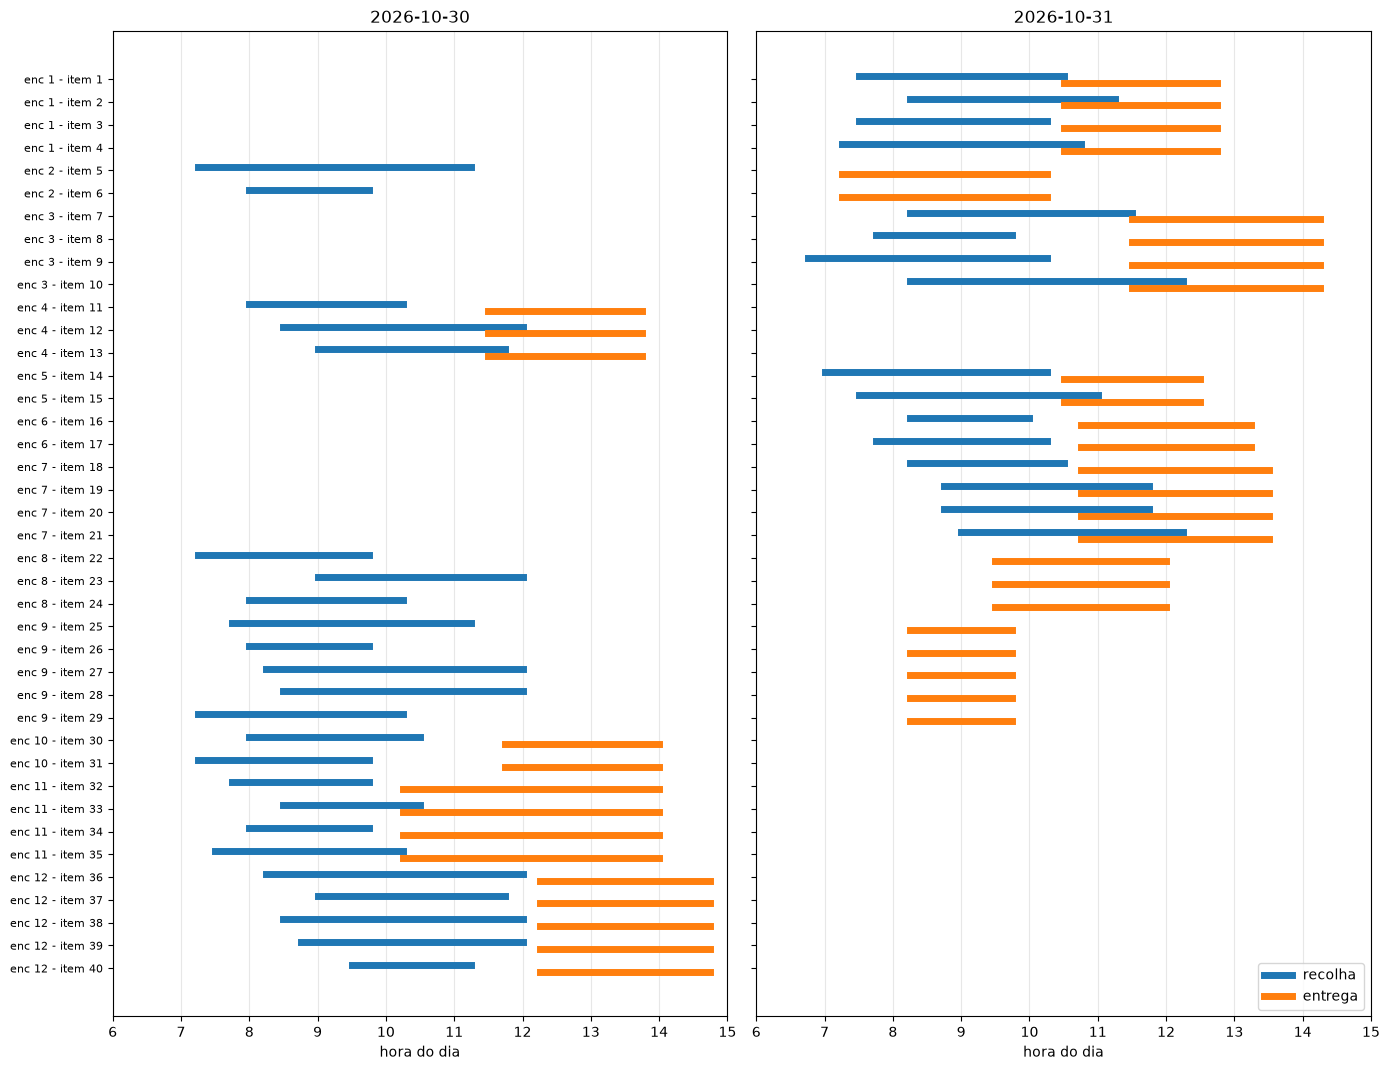

In [22]:
# hora_decimal (windows.py) converte uma data em número: 09:45 -> 9.75
dias = sorted(pedidos["dia_entrega"].unique())
altura = 2 + 0.22 * len(pedidos)                             # mais itens -> gráfico mais alto
hora_inicio = int(pedidos["availability_start"].dt.hour.min())          # hora mais cedo de todas as janelas
hora_fim = int(pedidos["delivery_end"].dt.hour.max()) + 1               # hora mais tarde de todas as janelas
fig, eixos = plt.subplots(1, len(dias), figsize=(14, altura), sharey=True)

for eixo, dia in zip(eixos, dias):
    for posicao, item in pedidos.iterrows():
        if item["dia_recolha"] == dia:
            eixo.plot([hora_decimal(item["availability_start"]), hora_decimal(item["availability_end"])],
                      [posicao - 0.15, posicao - 0.15], color="tab:blue", linewidth=5)
        if item["dia_entrega"] == dia:
            eixo.plot([hora_decimal(item["delivery_start"]), hora_decimal(item["delivery_end"])],
                      [posicao + 0.15, posicao + 0.15], color="tab:orange", linewidth=5)
    eixo.set_title(str(dia))
    eixo.set_xlabel("hora do dia")
    eixo.set_xlim(hora_inicio, hora_fim)
    eixo.grid(axis="x", alpha=0.3)

eixos[0].set_yticks(range(len(pedidos)))
eixos[0].set_yticklabels([f"enc {o} - item {i}" for o, i in zip(pedidos["order_id"], pedidos["order_item_id"])], fontsize=8)
eixos[0].invert_yaxis()
eixos[1].plot([], [], color="tab:blue", linewidth=5, label="recolha")
eixos[1].plot([], [], color="tab:orange", linewidth=5, label="entrega")
eixos[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Observações:**
- Todas as janelas são válidas. As de recolha duram entre 1h45 e 4h e as de entrega entre 1h30 e 3h45.
- As recolhas acontecem todas de manhã.
- Em 10 itens a janela de entrega abre antes de a de recolha fechar: para os entregar a tempo é preciso recolhê-los cedo.
- 10 itens (encomendas 2, 8 e 9) são recolhidos no dia 30 e entregues no dia 31, ficando a noite no armazém.

### 1.10 Distâncias entre paragens

**Objetivo:** confirmar que a matriz de distâncias está completa e coerente.

Verificamos se existem todos os pares de paragens, se a distância de A a B é igual à de B a A (**simetria**) e se ir de A a C diretamente nunca é mais longo do que passar por B (**desigualdade triangular**). Esta última propriedade será usada para justificar as heurísticas da pesquisa informada.

In [23]:
n = len(locations)
print("Pares esperados:", n * (n - 1), "| pares na matriz:", len(distance_matrix))

# tabelas origem x destino, com 0 na diagonal
km = matriz_paragens(dados, "distance_km")
minutos = matriz_paragens(dados, "duration_min")

print("Matriz simétrica:", (km - km.T).abs().max().max() < 0.01)

Pares esperados: 72 | pares na matriz: 72
Matriz simétrica: True


In [24]:
# desigualdade triangular: km(a, c) <= km(a, b) + km(b, c) para todas as paragens
violacoes = 0
for a in km.index:
    for b in km.index:
        for c in km.index:
            if km.loc[a, c] > km.loc[a, b] + km.loc[b, c] + 0.02:   # tolerância: as distâncias estão arredondadas a 0,01 km
                violacoes += 1
print("Violações da desigualdade triangular:", violacoes)

Violações da desigualdade triangular: 0


In [25]:
print("Distância mínima:", distance_matrix["distance_km"].min(), "km")
print("Distância média: ", round(distance_matrix["distance_km"].mean(), 1), "km")
print("Distância máxima:", distance_matrix["distance_km"].max(), "km")

# velocidade usada para calcular os tempos (ignora pares com distância 0)
com_distancia = distance_matrix[distance_matrix["duration_min"] > 0]
velocidade = com_distancia["distance_km"] / (com_distancia["duration_min"] / 60)
print("Velocidade implícita:", round(velocidade.mean()), "km/h | velocidade dos veículos:", vehicles["avg_speed_kmh"].tolist())

Distância mínima: 0.0 km
Distância média:  33.5 km
Distância máxima: 71.54 km
Velocidade implícita: 45 km/h | velocidade dos veículos: [45.0, 45.0]


In [26]:
# pares de paragens com distância zero
distance_matrix[distance_matrix["distance_km"] == 0]

,origin_location_id,origin_type,destination_location_id,destination_type,distance_km,duration_min
55,7,delivery_location,9,delivery_location,0.0,0.0
70,9,delivery_location,7,delivery_location,0.0,0.0


Para cada paragem calculamos a distância ao armazém e qual é a paragem mais próxima. Esta informação será útil para as heurísticas da pesquisa informada.

In [27]:
nomes = locations.set_index("location_id")["name"]
linhas = []
for paragem in km.index:
    outras = km.loc[paragem].drop(paragem)                    # distâncias para as outras paragens
    mais_proxima = outras.idxmin()
    linhas.append({"paragem": paragem, "nome": nomes[paragem],
                   "km ao armazém": km.loc[paragem, ARMAZEM],
                   "paragem mais próxima": f"{mais_proxima} {nomes[mais_proxima]}",
                   "km à mais próxima": outras.min()})
proximidade = pd.DataFrame(linhas).set_index("paragem")
proximidade

,nome,km ao armazém,paragem mais próxima,km à mais próxima
paragem,,,,
1,Hortas Valente,30.60,5 Loja 1,13.45
2,Campos Leite,37.66,1 Hortas Valente,23.59
3,Horta Morais,29.06,2 Campos Leite,26.05
4,Centro de Recolha 1,0.00,5 Loja 1,18.79
5,Loja 1,18.79,7 Casa 3,6.66
6,Casa 2,36.12,4 Centro de Recolha 1,36.12
7,Casa 3,23.53,9 Loja 5,0.00
8,Casa 4,21.39,4 Centro de Recolha 1,21.39
9,Loja 5,23.53,7 Casa 3,0.00


**Observações:**
- A matriz está completa (72 pares para 9 paragens), é simétrica e não tem nenhuma violação da desigualdade triangular.
- As distâncias variam entre 0 e 71,5 km. Os tempos foram calculados a 45 km/h, a mesma velocidade dos veículos.
- As paragens 7 (Casa 3) e 9 (Loja 5) estão no mesmo local em Guimarães, com distância 0: podem ser servidas na mesma passagem.
- A paragem 4 é o armazém, em Braga. A paragem mais próxima dele é a Loja 1 (18,8 km) e a mais afastada é o produtor Campos Leite (37,7 km).
- A Casa 2 (Esposende) e a Casa 4 (Famalicão) estão isoladas: a paragem mais próxima de ambas é o próprio armazém. Provavelmente serão servidas em viagens próprias.

### 1.11 Carga e capacidade dos veículos

**Objetivo:** comparar o peso a transportar com a capacidade dos veículos.

Como todos os produtos passam pelo armazém, separamos a carga das viagens de **recolha** (produtores → armazém) da carga das viagens de **entrega** (armazém → clientes).

In [28]:
carga = pd.DataFrame({
    "recolhas_kg": pedidos.groupby("dia_recolha")["weight_kg"].sum(),
    "entregas_kg": pedidos.groupby("dia_entrega")["weight_kg"].sum(),
}).rename_axis("dia")
carga

,recolhas_kg,entregas_kg
dia,,
2026-10-30,166.9,104.6
2026-10-31,103.1,165.4


In [29]:
print("Peso total:", pedidos["weight_kg"].sum(), "kg")
print("Capacidade dos veículos:", vehicles["capacity_kg"].tolist(), "kg | total:", vehicles["capacity_kg"].sum(), "kg")
print("Maior encomenda:", round(encomendas["peso_kg"].max(), 1), "kg")
print("Capacidade do armazém:", collection_centers["capacity_kg"].iloc[0], "kg")

Peso total: 270.0 kg
Capacidade dos veículos: [150.0, 200.0] kg | total: 350.0 kg
Maior encomenda: 51.1 kg
Capacidade do armazém: 5000.0 kg


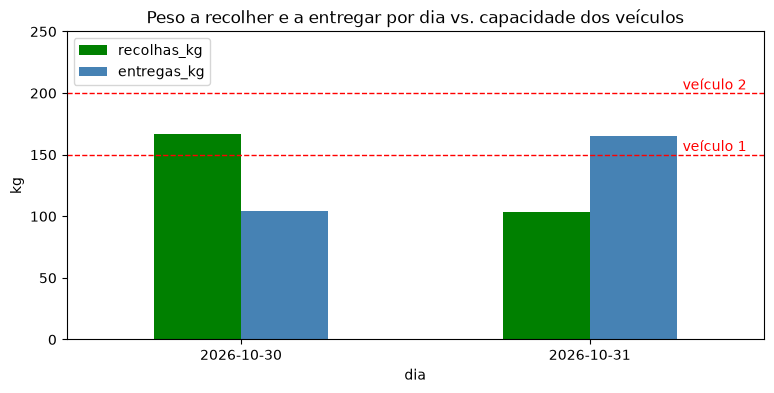

In [30]:
carga.plot.bar(figsize=(9, 4), rot=0, color=["green", "steelblue"])
for _, veiculo in vehicles.iterrows():
    plt.axhline(veiculo["capacity_kg"], color="red", linestyle="--", linewidth=1)
    plt.text(len(carga) - 0.55, veiculo["capacity_kg"] + 3, f"veículo {veiculo['vehicle_id']}", color="red", ha="right")
plt.ylim(0, 1.25 * max(carga.max().max(), vehicles["capacity_kg"].max()))   # espaço acima da barra mais alta
plt.title("Peso a recolher e a entregar por dia vs. capacidade dos veículos")
plt.ylabel("kg")
plt.legend(loc="upper left")
plt.show()

**Observações:**
- No total há 270 kg para uma frota de 350 kg (150 + 200 kg).
- No dia 30 há **166,9 kg para recolher**, mais do que a capacidade do veículo 1 (150 kg). No dia 31 há 165,4 kg para entregar.
- **A capacidade é uma restrição real**: a carga terá de ser dividida entre os dois veículos ou feita em mais do que uma viagem.
- A maior encomenda (51,1 kg) cabe em qualquer veículo, e o armazém (5000 kg) nunca é limitante.

### 1.12 Viabilidade dos pedidos

**Objetivo:** verificar se cada pedido pode ser cumprido, pelo menos isoladamente, respeitando as regras.

Os cálculos estão no módulo `windows.py`, nas funções `calcular_folgas` e `calcular_permanencias`. Ambas usam a função `tempo_viagem`, que lê da matriz os minutos de viagem entre duas paragens.

**Itens entregues no próprio dia.** Consideramos o melhor caso: o veículo recolhe o produto assim que fica disponível e segue sem desvios pelo percurso produtor → armazém → cliente. Somamos todos os tempos e calculamos a **folga**, isto é, quanto tempo sobra entre a chegada ao cliente e o fecho da janela de entrega. Uma folga negativa significaria que o pedido é impossível.

Para medir o custo da passagem obrigatória pelo armazém, calculamos também a folga se o produto fosse levado **diretamente** do produtor ao cliente.

In [31]:
# duração = 10 min de recolha + viagem ao armazém + 15 + 15 min no armazém + viagem ao cliente
folgas = calcular_folgas(pedidos, minutos, ARMAZEM, TEMPO_SERVICO, TEMPO_ARMAZEM)
print("Itens analisados:", len(folgas))
print("Impossíveis indo direto:       ", (folgas["folga_direta_min"] < 0).sum())
print("Impossíveis passando no armazém:", (folgas["folga_min"] < 0).sum())
print("Folga perdida, em média, por passar no armazém:",
      round((folgas["folga_direta_min"] - folgas["folga_min"]).mean()), "min")
folgas.head()

Itens analisados: 30
Impossíveis indo direto:        0
Impossíveis passando no armazém: 0
Folga perdida, em média, por passar no armazém: 64 min


,item,duracao_min,chegada,fecho_entrega,folga_direta_min,folga_min
1,2,112.2,2026-10-31 10:07:00,2026-10-31 12:45:00,250.2,157.8
18,21,112.2,2026-10-31 10:52:00,2026-10-31 13:30:00,250.2,157.8
16,19,112.2,2026-10-31 10:37:00,2026-10-31 13:30:00,265.2,172.8
10,13,112.2,2026-10-30 10:52:00,2026-10-30 13:45:00,265.2,172.8
17,20,112.2,2026-10-31 10:37:00,2026-10-31 13:30:00,265.2,172.8


**Itens entregues no dia seguinte.** Estes produtos passam a noite no armazém e não podem ficar lá mais de 24 h (desde que chegam até começarem a ser carregados). Calculamos a permanência:
- **mínima** — recolher o mais tarde possível e carregar apenas a tempo de chegar quando a janela de entrega abre;
- **máxima** — recolher o mais cedo possível e carregar o mais tarde possível.

In [32]:
permanencias = calcular_permanencias(pedidos, minutos, ARMAZEM, TEMPO_SERVICO, TEMPO_ARMAZEM)
print("Itens impossíveis (mínima > 24 h):", (permanencias["permanencia_min_h"] > PERMANENCIA_MAX).sum())
print("Itens com horários proibidos (máxima > 24 h):", (permanencias["permanencia_max_h"] > PERMANENCIA_MAX).sum())
permanencias

Itens impossíveis (mínima > 24 h): 0
Itens com horários proibidos (máxima > 24 h): 8


,item,encomenda,permanencia_min_h,permanencia_max_h
0,5,2,18.43,25.43
1,6,2,19.96,24.71
2,22,8,21.89,26.89
3,23,8,19.44,24.94
4,24,8,21.39,26.14
5,25,9,19.38,24.38
6,26,9,20.91,24.16
7,27,9,18.47,23.72
8,28,9,18.47,23.47
9,29,9,20.41,24.91


**Observações:**
- Os 30 itens entregues no próprio dia são todos exequíveis: mesmo passando pelo armazém, têm no mínimo 158 min de folga (itens 2 e 21).
- A passagem obrigatória pelo armazém retira, em média, 64 min de folga a cada item, mas não torna nenhum pedido impossível.
- Os 10 itens entregues no dia seguinte também são exequíveis, porque a permanência mínima (entre 18,5 e 21,9 h) é sempre inferior a 24 h.
- No entanto, em 8 desses itens a permanência máxima ultrapassa as 24 h. Ou seja, nem todas as combinações de horários são permitidas: recolher muito cedo no dia 30 obriga a entregar cedo no dia 31. O limite de 24 h é, por isso, uma restrição ativa que terá de ser modelada no CSP.

### 1.13 Comparação com o conjunto *small*

**Objetivo:** antecipar como o problema cresce no conjunto de dados maior.

In [33]:
# a mesma função de leitura serve para o outro conjunto de dados
small = carregar_dados("docs/data_small_30_31oct2026/")
small_orders = small["orders"]
small_items = small["order_items"]
small_vehicles = small["vehicles"]
small_locations = small["locations"]

comparacao = pd.DataFrame({
    "tiny":  [len(locations), len(orders), len(order_items),
              round(order_items["weight_kg"].sum(), 1), vehicles["capacity_kg"].sum()],
    "small": [len(small_locations), len(small_orders), len(small_items),
              round(small_items["weight_kg"].sum(), 1), small_vehicles["capacity_kg"].sum()],
}, index=["paragens", "encomendas", "itens", "peso total (kg)", "capacidade da frota (kg)"], dtype=object)
comparacao

,tiny,small
paragens,9,14
encomendas,12,25
itens,40,80
peso total (kg),270.0,580.0
capacidade da frota (kg),350.0,550.0


**Observações:** o conjunto *small* tem o dobro das encomendas e dos itens. O peso total (580 kg) é superior à capacidade da frota (550 kg), pelo que aí os veículos terão obrigatoriamente de fazer várias viagens.

### 1.14 Conclusões da EDA

1. **Os dados estão corretos.** Foram lidos sem erros e não têm valores em falta, repetidos ou referências inválidas. Ficam em memória em dicionários e listas do Python, prontos para os algoritmos.
2. **O problema é pequeno**: 9 paragens, 12 encomendas e 40 itens (270 kg) em 2 dias, com 2 veículos. Isto permite usar algoritmos exatos (UCS e A\*) para validar os resultados.
3. **O armazém é um ponto obrigatório.** Cada encomenda junta produtos de vários produtores e é entregue de uma só vez, por isso os produtos são reunidos no armazém. Esta passagem custa, em média, 64 min de folga por item.
4. **A capacidade conta.** No dia 30 as recolhas (166,9 kg) excedem a capacidade do veículo 1.
5. **As janelas temporais e o limite de 24 h no armazém são as restrições principais.** Todos os pedidos são exequíveis, mas algumas combinações de horários não são permitidas.
6. **A matriz de distâncias respeita a desigualdade triangular**, o que permite construir heurísticas admissíveis para o A\*.
7. **Ponto a confirmar:** o veículo 1 é refrigerado, mas nenhum produto indica precisar de frio. Assumimos que ambos os veículos podem transportar qualquer produto.